# Novelty detection: LOF on every trained latent

The awareness layer's first question is whether a window of movement is *unfamiliar*. The ankle paper answers it with
Local Outlier Factor (LOF) on an autoencoder's latent space: a window whose neighbourhood in the latent is sparser than
its neighbours' is scored as unfamiliar. This notebook scores every latent model trained so far and asks how well
each one flags movement it never saw, on people it never saw. It picks up new runs and new scores automatically
(section 7).

**What counts as familiar.** Every model was trained on the four ID-safe tasks (normal, incline and weighted walking,
stairs) of 14 participants. On the four **test participants** (BT07, BT15, BT19, BT22), those four tasks are
*familiar*; the other 22 tasks are *unfamiliar*: 18 OOD-safe tasks (moment-estimator territory) and 4 OOD-dangerous
ones (ball toss, step-ups, tug of war, sit-to-stand).

**Protocol, fixed before any model was scored** (`_novelty_scores.py`):

| step | rule |
|---|---|
| fit and calibrate | each run's exported training windows (20,000, ID-safe tasks, training participants), split 75 / 25 with a fixed seed: the score is fitted on the first part, its threshold set on the second |
| threshold | the 99.5th percentile of the calibration scores (the ankle paper's rule) |
| test windows | in-task windows of the test participants that every model exported (those with 3 s of clean history, so 1 s and 3 s models are scored on the same windows) |
| filter | the ankle paper's causal median over the last 0.5 s of the same recording, applied before the threshold |
| primary metric | AUROC, unfamiliar against familiar windows (per-window scores, threshold-free) |
| at the threshold | share of unfamiliar and OOD-dangerous windows flagged, and the false-alarm rate on familiar windows |

Scores compared: **LOF on the raw latent** (the ankle paper's score, k = 20, from `ml/common/models/autoencoder.py`),
**LOF on the standardized latent** (each unit scaled by its training mean and SD, so a block of large co-firing units
cannot dominate the distances), and **reconstruction error**, the paper's rejected score, as a reference. Every number
is a mean over three seeds unless stated. Section 6 moves the threshold and the latent's dimensionality to the
validation participants, so the test participants are scored once.

## Findings at a glance

- **LOF works best on the vanilla latents.** AUROC for unfamiliar against familiar windows is 0.893 ± 0.010 on the
  vanilla AE with 3 s + spectral inputs and 0.887 ± 0.010 on the vanilla AE with 1 s inputs; for the OOD-dangerous
  tasks the 1 s vanilla is best (0.968 ± 0.008, against 0.928 for 3 s + spectral).
- **The sparse latents are worse for LOF in every setting** (0.77 to 0.85). Their variance sits in one block of
  co-firing units (notebook 01, section 5), so neighbourhoods carry little beyond that block. Standardizing the latent
  per unit does not rescue them (within 0.02 of raw LOF for every model).
- **Reshaping the latent to 8 filters x 4 steps hurts** (0.825 vanilla, 0.774 sparse).
- **Reconstruction error is poor on 1 s windows (0.56 to 0.57), as the ankle paper found, but fair with 3 s + spectral
  inputs (0.68 to 0.78).** An unfamiliar rhythm in the constant spectral channels cannot be reconstructed. It still
  trails LOF on the vanilla latents.
- **At the ankle paper's threshold most unfamiliar windows pass unflagged.** The best models flag 29 to 36% of
  unfamiliar windows and up to 45% of OOD-dangerous ones, at 1.6 to 2.2% false alarms on familiar windows, above the
  0.5% the threshold targets on training people. Unfamiliar scores straddle the threshold (section 5), so the
  operating point, not the ranking, is what limits recall.
- **Quiet movement is the blind spot.** Jumping, running and cutting are flagged most; standing poses and the ball toss
  (OOD-dangerous) least, as are near-familiar tasks such as obstacle and dynamic walking. Of the dangerous tasks,
  step-ups are flagged best (35 to 73% of windows; 56 to 73% on the vanilla latents), sit-to-stand and tug of war
  partly, the ball toss rarely (4 to 23%).
- **Choosing the threshold and the latent's dimensionality on held-out people (section 6) moves the operating point
  more than the detector.** A 1% false-alarm target set on the validation participants lands at 1.7 to 2.0% on the
  test participants, so the familiar score level is wearer-specific. At matched false alarms the vanilla 1 s latent
  gains about 5 points of recall from LOF on 16 principal components (34% of unfamiliar and 53% of OOD-dangerous
  windows at 1.7% false alarms, within seed noise), the other latents gain nothing from fewer dimensions, and the
  false-alarm target itself is the lever: 2% buys 44% and 63%, 5% buys 61% and 81%.

In [1]:
import json
import sys
import time
from functools import reduce
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _novelty_scores as ns

RUNS = REPO / 'notebooks' / 'nature' / 'model_exploration' / 'runs'      # every exported run below here is scored
DATA = REPO / 'data' / 'processed_nature' / 'ae'
CACHE = REPO / 'data' / 'cache' / 'nature' / 'novelty'                   # scores, keyed by each export's content
FAMILIAR = nt.ID_SAFE_TASKS
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
runs = ns.discover_runs(RUNS)
sort_key = lambda c: (c.get('inputs', ''), c.get('latent', '4x8'), c.get('variant', ''), c.get('sparsity_weight', 0))   # noqa: E731
MODEL_ORDER = list(dict.fromkeys(runs.assign(k = runs['config'].map(sort_key)).sort_values(['family', 'k'])['model']))
print(f'{len(runs)} runs of {len(MODEL_ORDER)} models; scores: {list(ns.SCORES)}')

21 runs of 7 models; scores: ['LOF, raw latent', 'LOF, standardized latent', 'reconstruction error']


## 1. Models and windows

Each model's validation reconstruction error and sparsity come from training (validation participants, familiar
tasks); they are context, not part of the comparison.

In [2]:
rows = []
for model in MODEL_ORDER:
    group = runs[runs['model'] == model]
    s = [json.loads((r / 'summary.json').read_text()) for r in group['run']]
    rows.append({'model': model, 'family': group['family'].iloc[0], 'seeds': len(group), 'run stem': group['stem'].iloc[0],
                 'val MSE': np.mean([x['val_mse'] for x in s]), 'val scale-free L1': np.mean([x['val_penalty'] for x in s])})
display(pd.DataFrame(rows).set_index('model').round(3))

exports = {r.run: ns.load_export(r.run, tables[r.inputs]) for r in runs.itertuples()}
test_labels = {run: e['labels'][~e['is_train']].reset_index(drop = True) for run, e in exports.items()}
keys = [pd.MultiIndex.from_frame(t[['rec', 'end']]) for t in test_labels.values()]
COMMON = reduce(lambda a, b: a.intersection(b), keys)               # windows every run exported
first = next(iter(test_labels.values()))
shown = first[pd.MultiIndex.from_frame(first[['rec', 'end']]).isin(COMMON)]
print(f'{len(COMMON):,} test windows common to every run (participants {sorted(shown.subject.astype(str).unique())})')
display(shown.groupby('controller_class', observed = True).size().rename('windows').to_frame().T)

,family,seeds,run stem,val MSE,val scale-free L1
model,,,,,
sparse · 1 s raw · λ 0.3,ae,3,sparse,0.313,0.249
vanilla · 1 s raw,ae,3,vanilla,0.247,0.902
sparse · 3 s + spectral · λ 0.1,ae,3,sparse_raw_3s_spectral_l0.1,0.285,0.273
sparse · 3 s + spectral · λ 0.3,ae,3,sparse_raw_3s_spectral,0.306,0.104
vanilla · 3 s + spectral,ae,3,vanilla_raw_3s_spectral,0.269,0.839
sparse · 3 s + spectral · λ 0.1 · 8x4,ae,3,sparse_raw_3s_spectral_l0.1_8x4,0.358,0.139
vanilla · 3 s + spectral · 8x4,ae,3,vanilla_raw_3s_spectral_8x4,0.353,0.612


137,955 test windows common to every run (participants ['BT07', 'BT15', 'BT19', 'BT22'])


controller_class,ID-safe,OOD-dangerous,OOD-safe
windows,24860,16606,96489


## 2. Scoring

Every run, every score. Scores are cached by the export's content, so rerunning only computes what is new.

In [3]:
t0 = time.time()
results, per_task = [], []
for r in runs.itertuples():
    labels = test_labels[r.run]
    keep = pd.MultiIndex.from_frame(labels[['rec', 'end']]).isin(COMMON)
    for score in ns.SCORES:
        cal, test = ns.get_scores(r.run, exports[r.run], score, CACHE)
        metrics, flagged = ns.evaluate(cal, test[keep], labels[keep].reset_index(drop = True), FAMILIAR)
        results.append({'model': r.model, 'seed': r.seed, 'score': score, **metrics})
        per_task.append(flagged.rename((r.model, r.seed, score)))
results = pd.DataFrame(results)
per_task = pd.DataFrame(per_task)
per_task.index = pd.MultiIndex.from_tuples(per_task.index, names = ['model', 'seed', 'score'])
print(f'scored {len(runs)} runs x {len(ns.SCORES)} scores in {time.time() - t0:.0f} s')

scored 21 runs x 3 scores in 6 s


## 3. Detection, model by model

Mean ± SD over seeds. AUROC is threshold-free: 0.5 is chance, 1 a perfect ranking of unfamiliar above familiar
windows. The flagged shares use the filtered score against the calibration threshold.

In [4]:
METRICS = [c for c in results if c not in ('model', 'seed', 'score')]
agg = results.groupby(['score', 'model'], sort = False)[METRICS].agg(['mean', 'std'])
for score in ns.SCORES:
    part = agg.loc[score].reindex(MODEL_ORDER)
    fmt = lambda c: '{:.3f}' if c.startswith('AUROC') else '{:.1f}'   # noqa: E731
    table = pd.DataFrame({c: part[(c, 'mean')].map(fmt(c).format) + ' ± ' + part[(c, 'std')].map(fmt(c).format) for c in METRICS})
    print(score); display(table)

LOF, raw latent


,"AUROC, unfamiliar vs familiar","AUROC, OOD-dangerous vs familiar","flagged, unfamiliar (%)","flagged, OOD-dangerous (%)","false alarms, familiar (%)"
model,,,,,
sparse · 1 s raw · λ 0.3,0.846 ± 0.011,0.941 ± 0.021,16.8 ± 0.4,32.2 ± 7.4,1.0 ± 0.2
vanilla · 1 s raw,0.887 ± 0.010,0.968 ± 0.008,29.2 ± 4.0,44.9 ± 7.1,1.6 ± 0.4
sparse · 3 s + spectral · λ 0.1,0.811 ± 0.018,0.830 ± 0.043,30.1 ± 7.7,36.6 ± 10.8,2.5 ± 0.5
sparse · 3 s + spectral · λ 0.3,0.794 ± 0.029,0.818 ± 0.044,27.8 ± 4.3,38.0 ± 7.5,2.4 ± 0.3
vanilla · 3 s + spectral,0.893 ± 0.010,0.928 ± 0.013,36.2 ± 5.5,40.3 ± 4.5,2.2 ± 1.0
sparse · 3 s + spectral · λ 0.1 · 8x4,0.774 ± 0.040,0.777 ± 0.068,30.5 ± 7.4,38.0 ± 10.1,1.9 ± 0.9
vanilla · 3 s + spectral · 8x4,0.825 ± 0.034,0.855 ± 0.060,23.9 ± 3.4,27.1 ± 5.0,1.8 ± 0.5


LOF, standardized latent


,"AUROC, unfamiliar vs familiar","AUROC, OOD-dangerous vs familiar","flagged, unfamiliar (%)","flagged, OOD-dangerous (%)","false alarms, familiar (%)"
model,,,,,
sparse · 1 s raw · λ 0.3,0.838 ± 0.022,0.910 ± 0.077,12.8 ± 5.8,21.0 ± 16.9,0.9 ± 0.4
vanilla · 1 s raw,0.882 ± 0.012,0.963 ± 0.009,27.4 ± 3.5,40.8 ± 6.2,1.5 ± 0.5
sparse · 3 s + spectral · λ 0.1,0.792 ± 0.022,0.812 ± 0.021,25.2 ± 7.6,34.2 ± 9.7,2.2 ± 0.6
sparse · 3 s + spectral · λ 0.3,0.799 ± 0.024,0.841 ± 0.031,27.4 ± 9.5,42.4 ± 10.0,1.9 ± 1.3
vanilla · 3 s + spectral,0.883 ± 0.013,0.918 ± 0.019,34.2 ± 4.5,37.1 ± 7.0,2.3 ± 0.9
sparse · 3 s + spectral · λ 0.1 · 8x4,0.761 ± 0.045,0.765 ± 0.091,27.4 ± 3.0,36.8 ± 6.9,2.1 ± 1.5
vanilla · 3 s + spectral · 8x4,0.831 ± 0.033,0.863 ± 0.065,25.3 ± 3.5,34.8 ± 9.2,1.8 ± 0.7


reconstruction error


,"AUROC, unfamiliar vs familiar","AUROC, OOD-dangerous vs familiar","flagged, unfamiliar (%)","flagged, OOD-dangerous (%)","false alarms, familiar (%)"
model,,,,,
sparse · 1 s raw · λ 0.3,0.555 ± 0.009,0.717 ± 0.028,8.0 ± 2.9,12.8 ± 12.0,1.4 ± 0.2
vanilla · 1 s raw,0.570 ± 0.011,0.727 ± 0.017,7.7 ± 3.7,14.5 ± 12.4,1.4 ± 0.3
sparse · 3 s + spectral · λ 0.1,0.776 ± 0.016,0.892 ± 0.037,14.3 ± 6.8,22.4 ± 22.6,1.5 ± 0.3
sparse · 3 s + spectral · λ 0.3,0.781 ± 0.010,0.900 ± 0.025,16.6 ± 2.4,33.8 ± 6.1,1.3 ± 0.4
vanilla · 3 s + spectral,0.759 ± 0.028,0.860 ± 0.042,12.8 ± 3.1,17.7 ± 12.0,1.3 ± 0.2
sparse · 3 s + spectral · λ 0.1 · 8x4,0.714 ± 0.017,0.830 ± 0.023,9.1 ± 1.5,9.5 ± 4.1,0.7 ± 0.2
vanilla · 3 s + spectral · 8x4,0.677 ± 0.013,0.744 ± 0.020,7.5 ± 0.5,2.0 ± 0.5,0.8 ± 0.1


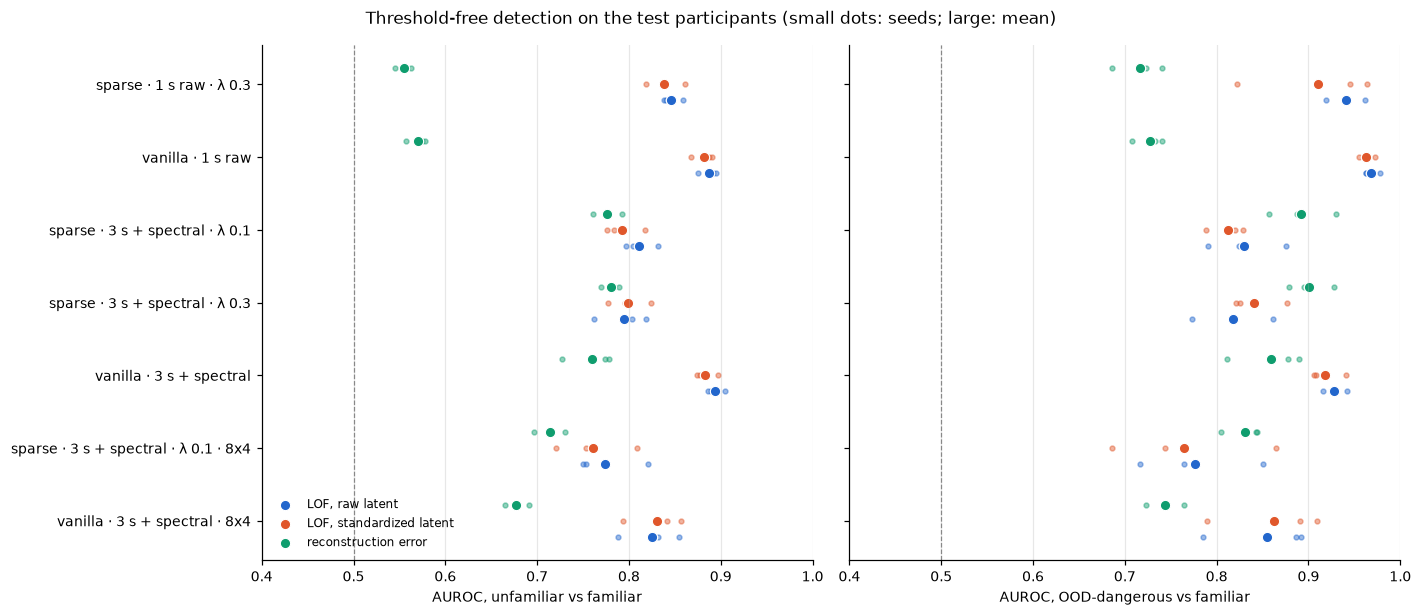

In [5]:
SCORE_C = dict(zip(ns.SCORES, ['#2266cc', '#e0572b', '#0f9d6e']))      # validated categorical palette (latent notebook)
fig, axes = plt.subplots(1, 2, figsize = (13, 0.55 * len(MODEL_ORDER) + 1.8), sharey = True)
y = {m: i for i, m in enumerate(MODEL_ORDER[::-1])}
for ax, metric in zip(axes, ['AUROC, unfamiliar vs familiar', 'AUROC, OOD-dangerous vs familiar']):
    for k, (score, color) in enumerate(SCORE_C.items()):
        part = results[results['score'] == score]
        offset = (k - 1) * 0.22
        ax.scatter(part[metric], part['model'].map(y) + offset, s = 10, color = color, alpha = .45)
        means = part.groupby('model')[metric].mean()
        ax.scatter(means.values, means.index.map(y) + offset, s = 46, color = color, label = score, edgecolor = 'white', linewidth = .8)
    ax.axvline(0.5, color = '#888', lw = .8, ls = '--')
    ax.set(xlabel = metric, xlim = (0.4, 1.0))
    ax.grid(axis = 'x', alpha = .3)
axes[0].set_yticks(list(y.values()), list(y.keys()))
axes[0].legend(loc = 'lower left', fontsize = 8, frameon = False)
fig.suptitle('Threshold-free detection on the test participants (small dots: seeds; large: mean)', fontsize = 11)
plt.tight_layout(); plt.show()

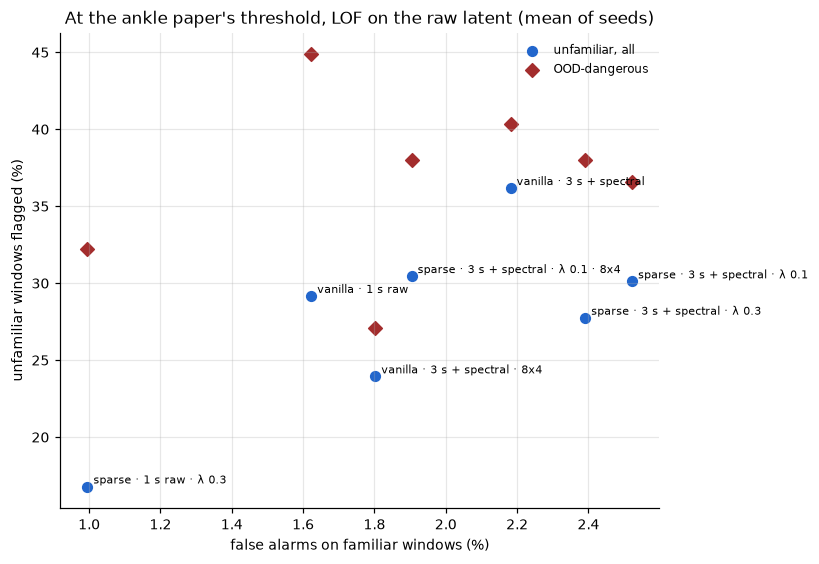

In [6]:
fig, ax = plt.subplots(figsize = (7.5, 5.2))
part = results[results['score'] == 'LOF, raw latent'].groupby('model')[['false alarms, familiar (%)', 'flagged, unfamiliar (%)',
                                                                        'flagged, OOD-dangerous (%)']].mean().reindex(MODEL_ORDER)
ax.scatter(part['false alarms, familiar (%)'], part['flagged, unfamiliar (%)'], s = 40, color = '#2266cc', label = 'unfamiliar, all')
ax.scatter(part['false alarms, familiar (%)'], part['flagged, OOD-dangerous (%)'], s = 40, color = '#a32d2d', marker = 'D', label = 'OOD-dangerous')
for m, row in part.iterrows():
    ax.annotate(m, (row['false alarms, familiar (%)'], row['flagged, unfamiliar (%)']), fontsize = 7, xytext = (4, 2), textcoords = 'offset points')
ax.set(xlabel = 'false alarms on familiar windows (%)', ylabel = 'unfamiliar windows flagged (%)',
       title = 'At the ankle paper\'s threshold, LOF on the raw latent (mean of seeds)')
ax.legend(fontsize = 8, frameon = False); ax.grid(alpha = .3); plt.tight_layout(); plt.show()

## 4. Task by task

Share of each task's test windows flagged as unfamiliar (filtered score above the threshold), mean of seeds. The first
four columns are the familiar tasks, so their values are false alarms; for every other column higher is better.

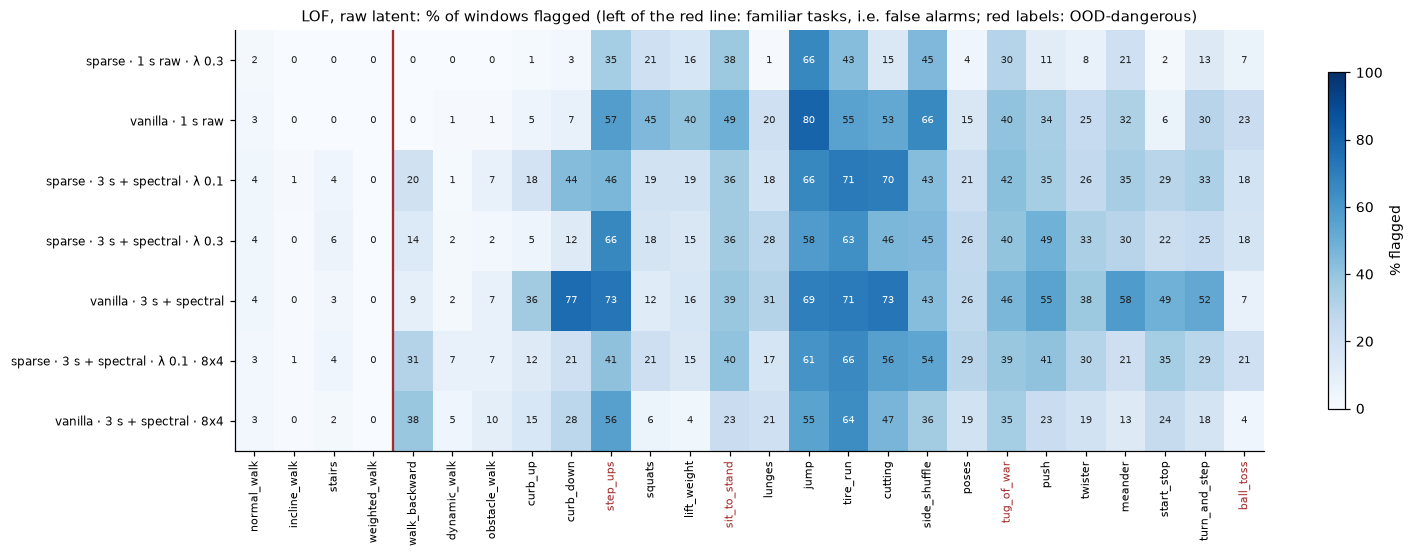

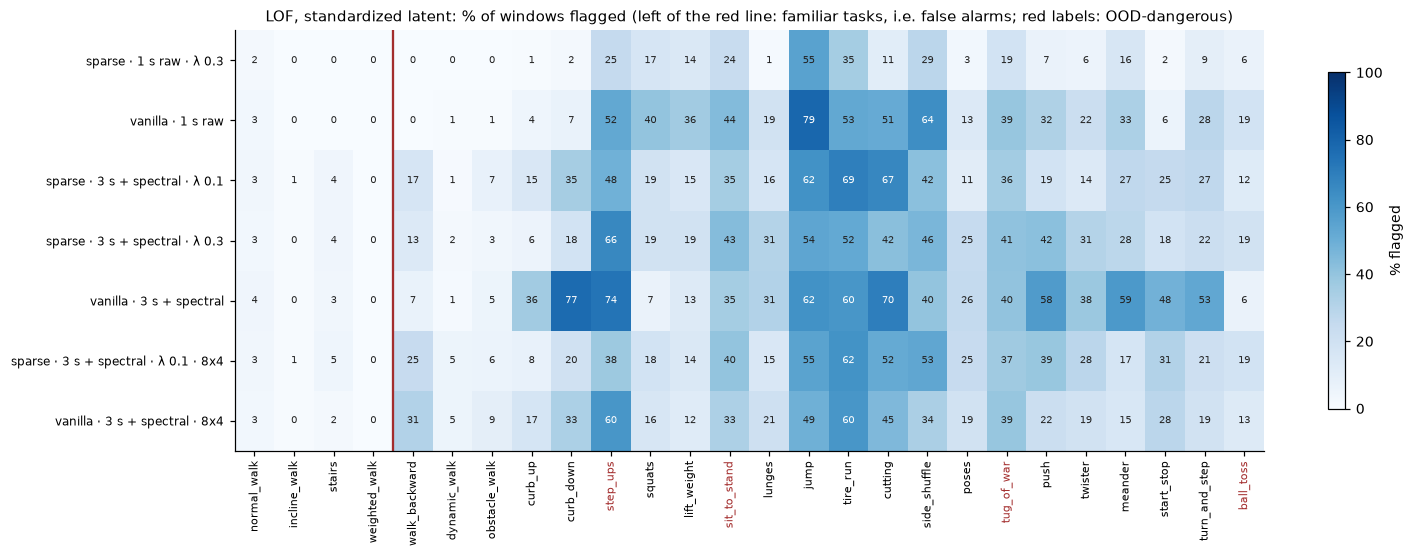

In [7]:
TASKS = list(FAMILIAR) + [t for ts in nt.TASK_FAMILIES.values() for t in ts if t not in FAMILIAR]
for score in ('LOF, raw latent', 'LOF, standardized latent'):
    grid = per_task.xs(score, level = 'score').groupby(level = 'model').mean().reindex(index = MODEL_ORDER, columns = TASKS)
    fig, ax = plt.subplots(figsize = (14, 0.42 * len(MODEL_ORDER) + 2.2))
    im = ax.imshow(grid.to_numpy(), aspect = 'auto', cmap = 'Blues', vmin = 0, vmax = 100)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            ax.text(j, i, f'{v:.0f}', ha = 'center', va = 'center', fontsize = 6.5, color = 'white' if v > 60 else '#222')
    ax.set_xticks(range(len(TASKS)), TASKS, rotation = 90, fontsize = 7.5)
    ax.set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER, fontsize = 8)
    ax.axvline(len(FAMILIAR) - .5, color = '#a32d2d', lw = 1.5)
    for t in nt.OOD_DANGEROUS_TASKS:
        ax.get_xticklabels()[TASKS.index(t)].set_color('#a32d2d')
    ax.set_title(f'{score}: % of windows flagged (left of the red line: familiar tasks, i.e. false alarms; red labels: OOD-dangerous)', fontsize = 9.5)
    fig.colorbar(im, ax = ax, shrink = .8, label = '% flagged'); plt.tight_layout(); plt.show()

## 5. Where the scores fall

For the model with the best mean AUROC under LOF on the raw latent (seed 0): each task's filtered scores relative to
the threshold (1 = threshold, log scale). Boxes span the middle half of windows, whiskers 5 to 95%.

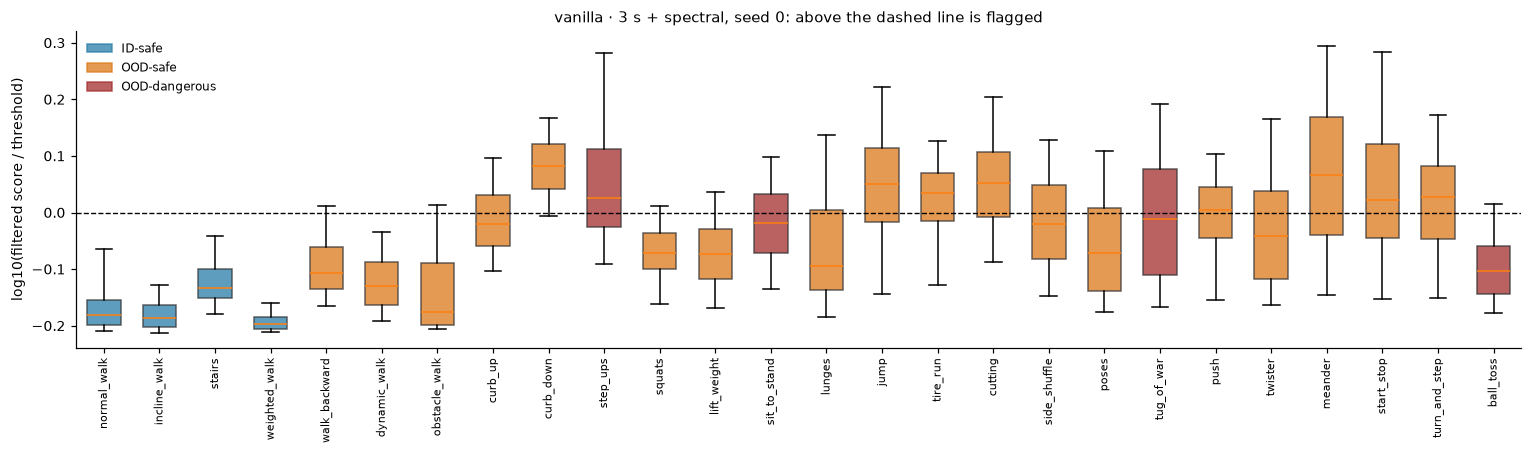

In [8]:
lof_raw = results[results['score'] == 'LOF, raw latent']
best = lof_raw.groupby('model')['AUROC, unfamiliar vs familiar'].mean().idxmax()
r = runs[(runs['model'] == best) & (runs['seed'] == 0)].iloc[0]
labels = test_labels[r.run]
keep = pd.MultiIndex.from_frame(labels[['rec', 'end']]).isin(COMMON)
cal, test = ns.get_scores(r.run, exports[r.run], 'LOF, raw latent', CACHE)
lab = labels[keep].reset_index(drop = True)
filtered = ns.get_causal_median(test[keep], lab['rec'].to_numpy(), lab['end'].to_numpy()) / np.percentile(cal, 99.5)
CLASS_C = {'ID-safe': '#287da8', 'OOD-safe': '#dd791a', 'OOD-dangerous': '#a32d2d'}
fig, ax = plt.subplots(figsize = (14, 4.2))
data = [np.log10(np.clip(filtered[lab['task'].astype(str).to_numpy() == t], 1e-3, None)) for t in TASKS]
bp = ax.boxplot(data, whis = (5, 95), showfliers = False, patch_artist = True, widths = .6)
for patch, t in zip(bp['boxes'], TASKS):
    patch.set(facecolor = CLASS_C[nt.get_controller_class(t)], alpha = .75, edgecolor = '#333')
ax.axhline(0, color = 'k', lw = .9, ls = '--')
ax.set_xticks(range(1, len(TASKS) + 1), TASKS, rotation = 90, fontsize = 7.5)
ax.set_ylabel('log10(filtered score / threshold)')
handles = [plt.Rectangle((0, 0), 1, 1, color = c, alpha = .75, label = k) for k, c in CLASS_C.items()]
ax.legend(handles = handles, fontsize = 8, frameon = False, loc = 'upper left')
ax.set_title(f'{best}, seed 0: above the dashed line is flagged', fontsize = 10)
plt.tight_layout(); plt.show()

## 6. The operating point on held-out people, and LOF in fewer dimensions

Sections 3 to 5 follow the ankle paper's rule: the threshold is the 99.5th percentile of the calibration scores of
*training* people, and LOF runs on all 32 latent units as exported. Section 7 of notebook 01 and section 5 here both
found that rule too cautious, and the Science Robotics VAE study found LOF better in fewer dimensions
(`ml/sci_rob/VAE/results/posthoc_dims.md`). Both choices are made here on the four **validation participants**
(BT09, BT12, BT13, BT21), whose latents come from each run's saved checkpoint through
`ml/nature/awareness/encode_split.py`, so the test participants stay untouched until the last step.

| step | rule |
|---|---|
| representation | the latent as exported (`raw`, as in sections 3 to 5); every unit standardized by the fit set (`all units`); or that standardized latent projected onto k principal components fitted on the fit set, k in {4, 6, 8, 12, 16, 24} |
| threshold | the filtered score that flags 1% of the familiar validation windows (the false-alarm target), per run |
| choice of k | per model, the representation with the highest mean recall of unfamiliar validation windows at that threshold; ties go to fewer dimensions |
| test | the chosen representation with each seed's own threshold, scored once on the test windows of section 1 |

LOF is still fitted on the fit part of each run's exported training windows (k = 20), and the 0.5 s causal median is
still applied before the threshold. Validation windows are those every run exported, as for test. Runs without
validation latents are listed and left out.

In [9]:
REPRESENTATIONS = ['raw', None, *ns.PCA_KS]
rep_label = lambda r: 'raw' if r == 'raw' else 'all units' if r is None else f'PCA-{r}'      # noqa: E731
DIMS = {'raw': 32, 'all units': 32, **{f'PCA-{k}': k for k in ns.PCA_KS}}
REP_BY_DIMS = sorted(DIMS, key = lambda r: (DIMS[r], r == 'raw'))                           # PCA-4 ... PCA-24, all units, raw

val_exports = {r.run: ns.load_split_export(r.run, tables[r.inputs]) for r in runs.itertuples()}
with_val = runs[runs['run'].map(lambda r: val_exports[r] is not None)]
missing = sorted(set(runs['model']) - set(with_val['model']))
print(f'{len(with_val)} runs of {with_val["model"].nunique()} models have validation latents' + (f'; without: {missing}' if missing else ''))
val_labels = {run: val_exports[run]['labels'] for run in with_val['run']}
COMMON_VAL = reduce(lambda a, b: a.intersection(b), [pd.MultiIndex.from_frame(l[['rec', 'end']]) for l in val_labels.values()])
first_val = next(iter(val_labels.values()))
shown_val = first_val[pd.MultiIndex.from_frame(first_val[['rec', 'end']]).isin(COMMON_VAL)]
print(f'{len(COMMON_VAL):,} validation windows common to every run (participants {sorted(shown_val.subject.astype(str).unique())})')
display(shown_val.groupby('controller_class', observed = True).size().rename('windows').to_frame().T)

t0 = time.time()
rows, per_task_tuned = [], []
for r in with_val.itertuples():
    labels_v, labels_t = val_labels[r.run], test_labels[r.run]
    keep_v = pd.MultiIndex.from_frame(labels_v[['rec', 'end']]).isin(COMMON_VAL)
    keep_t = pd.MultiIndex.from_frame(labels_t[['rec', 'end']]).isin(COMMON)
    lab_v, lab_t = labels_v[keep_v].reset_index(drop = True), labels_t[keep_t].reset_index(drop = True)
    for rep in REPRESENTATIONS:
        cal, val, test = ns.get_split_scores(r.run, exports[r.run], val_exports[r.run], rep, CACHE)
        threshold = ns.tune_threshold(ns.get_filtered(val[keep_v], lab_v), lab_v, FAMILIAR)
        ankle = float(np.percentile(cal, ns.THRESHOLD_PERCENTILE))
        m_val, _ = ns.evaluate_at(threshold, val[keep_v], lab_v, FAMILIAR)
        m_test, flagged = ns.evaluate_at(threshold, test[keep_t], lab_t, FAMILIAR)
        m_ankle, _ = ns.evaluate_at(ankle, test[keep_t], lab_t, FAMILIAR)
        rows.append({'model': r.model, 'seed': r.seed, 'representation': rep_label(rep), 'threshold': threshold, 'ankle threshold': ankle,
                     **{f'val {k}': v for k, v in m_val.items()}, **{f'test {k}': v for k, v in m_test.items()},
                     **{f'ankle test {k}': v for k, v in m_ankle.items()}})
        per_task_tuned.append(flagged.rename((r.model, r.seed, rep_label(rep))))
step1 = pd.DataFrame(rows)
per_task_tuned = pd.DataFrame(per_task_tuned)
per_task_tuned.index = pd.MultiIndex.from_tuples(per_task_tuned.index, names = ['model', 'seed', 'representation'])
print(f'scored {len(with_val)} runs x {len(REPRESENTATIONS)} representations in {time.time() - t0:.0f} s')

21 runs of 7 models have validation latents
173,590 validation windows common to every run (participants ['BT09', 'BT12', 'BT13', 'BT21'])


controller_class,ID-safe,OOD-dangerous,OOD-safe
windows,35345,22159,116086


scored 21 runs x 8 representations in 57 s


### 6.1 Choosing the representation on validation

Mean recall of unfamiliar validation windows at the 1% false-alarm threshold, by representation (columns in order of
dimension). The chosen column is the maximum; the test participants have not been looked at yet.

In [10]:
MODELS_VAL = [m for m in MODEL_ORDER if m in set(with_val['model'])]
val_recall = (step1.groupby(['model', 'representation'])['val flagged, unfamiliar (%)'].mean()
              .unstack().reindex(index = MODELS_VAL, columns = REP_BY_DIMS))
chosen = val_recall.idxmax(axis = 1)                                      # the first maximum: fewest dimensions on a tie
val_auroc = (step1.groupby(['model', 'representation'])['val AUROC, unfamiliar vs familiar'].mean()
             .unstack().reindex(index = MODELS_VAL, columns = REP_BY_DIMS))
print('recall of unfamiliar validation windows at 1% false alarms (%), mean of seeds')
display(val_recall.round(1).assign(chosen = chosen))
print('AUROC on validation, unfamiliar vs familiar (threshold-free), mean of seeds')
display(val_auroc.round(3))

recall of unfamiliar validation windows at 1% false alarms (%), mean of seeds


representation,PCA-4,PCA-6,PCA-8,PCA-12,PCA-16,PCA-24,all units,raw,chosen
model,,,,,,,,,
sparse · 1 s raw · λ 0.3,4.6,4.5,7.0,14.2,20.5,22.9,23.8,26.2,raw
vanilla · 1 s raw,6.6,16.0,22.2,29.4,33.2,31.6,30.4,31.6,PCA-16
sparse · 3 s + spectral · λ 0.1,23.9,26.7,26.9,32.1,29.8,29.8,30.3,30.1,PCA-12
sparse · 3 s + spectral · λ 0.3,19.7,22.7,28.6,31.3,30.8,31.9,31.9,34.1,raw
vanilla · 3 s + spectral,14.3,19.1,21.7,25.8,28.0,30.4,33.4,34.7,raw
sparse · 3 s + spectral · λ 0.1 · 8x4,28.2,30.8,28.6,32.4,32.1,33.1,33.1,33.9,raw
vanilla · 3 s + spectral · 8x4,14.2,23.6,24.6,25.7,21.8,23.5,24.4,24.2,PCA-12


AUROC on validation, unfamiliar vs familiar (threshold-free), mean of seeds


representation,PCA-4,PCA-6,PCA-8,PCA-12,PCA-16,PCA-24,all units,raw
model,,,,,,,,
sparse · 1 s raw · λ 0.3,0.516,0.514,0.548,0.689,0.764,0.805,0.818,0.830
vanilla · 1 s raw,0.686,0.757,0.798,0.844,0.860,0.867,0.862,0.867
sparse · 3 s + spectral · λ 0.1,0.696,0.706,0.724,0.785,0.786,0.793,0.794,0.804
sparse · 3 s + spectral · λ 0.3,0.695,0.695,0.710,0.749,0.774,0.779,0.779,0.779
vanilla · 3 s + spectral,0.725,0.748,0.775,0.799,0.820,0.841,0.854,0.864
sparse · 3 s + spectral · λ 0.1 · 8x4,0.725,0.749,0.743,0.752,0.755,0.764,0.764,0.764
vanilla · 3 s + spectral · 8x4,0.731,0.762,0.773,0.765,0.764,0.791,0.799,0.801


### 6.2 Test: the ankle rule against the tuned threshold

Three settings per model, mean ± SD over seeds, scored on the test participants: the ankle paper's rule on the raw
latent (sections 3 to 5); the tuned threshold on the raw latent (what the threshold alone buys); and the tuned
threshold in the representation chosen in 6.1 (what fewer dimensions add). False alarms are the share of familiar
test windows flagged; recall the share of unfamiliar or OOD-dangerous ones.

The figure after the table shows the dense latents only (plain and Gaussian-NLL, 4 x 8), one colour per
model throughout section 6; the sparse and 8 x 4 models are in the tables.

In [11]:
def get_setting_rows(frame, prefix, setting):
    """One tidy row per run for a (threshold rule, representation) setting."""
    out = pd.DataFrame({'model': frame['model'], 'seed': frame['seed'], 'setting': setting,
                        'false alarms (%)': frame[f'{prefix} false alarms, familiar (%)'],
                        'recall, unfamiliar (%)': frame[f'{prefix} flagged, unfamiliar (%)'],
                        'recall, OOD-dangerous (%)': frame[f'{prefix} flagged, OOD-dangerous (%)'],
                        'AUROC, unfamiliar': frame[f'{prefix} AUROC, unfamiliar vs familiar'],
                        'AUROC, OOD-dangerous': frame[f'{prefix} AUROC, OOD-dangerous vs familiar']})
    return out

raw = step1[step1['representation'] == 'raw']
at_chosen = step1[step1['representation'] == step1['model'].map(chosen)]
SETTINGS = ['ankle rule, raw latent', 'tuned threshold, raw latent', 'tuned threshold, chosen representation']
summary = pd.concat([get_setting_rows(raw, 'ankle test', SETTINGS[0]), get_setting_rows(raw, 'test', SETTINGS[1]),
                     get_setting_rows(at_chosen, 'test', SETTINGS[2])], ignore_index = True)
summary['validation false alarms (%)'] = pd.concat([raw['ankle test false alarms, familiar (%)'] * np.nan,
                                                   raw['val false alarms, familiar (%)'], at_chosen['val false alarms, familiar (%)']]).to_numpy()
COLS = ['false alarms (%)', 'recall, unfamiliar (%)', 'recall, OOD-dangerous (%)', 'AUROC, unfamiliar', 'AUROC, OOD-dangerous']
agg = summary.groupby(['model', 'setting'], sort = False)[COLS].agg(['mean', 'std'])
fmt = lambda c: '{:.3f}' if c.startswith('AUROC') else '{:.1f}'          # noqa: E731
table = pd.DataFrame({c: agg[(c, 'mean')].map(fmt(c).format) + ' ± ' + agg[(c, 'std')].map(fmt(c).format) for c in COLS})
table.insert(0, 'representation', [chosen[m] if s == SETTINGS[2] else 'raw' for m, s in table.index])
table = table.reindex(pd.MultiIndex.from_product([MODELS_VAL, SETTINGS], names = ['model', 'setting']))
display(table)

representation false alarms (%) recall, unfamiliar (%) recall, OOD-dangerous (%) AUROC, unfamiliar AUROC, OOD-dangerous
model                                 setting                                                                                                                                                       
sparse · 1 s raw · λ 0.3              ankle rule, raw latent                            raw        1.0 ± 0.2             16.8 ± 0.4                32.2 ± 7.4     0.846 ± 0.011        0.941 ± 0.021
                                      tuned threshold, raw latent                       raw        1.7 ± 0.1             26.9 ± 2.1                45.7 ± 5.9     0.846 ± 0.011        0.941 ± 0.021
                                      tuned threshold, chosen representation            raw        1.7 ± 0.1             26.9 ± 2.1                45.7 ± 5.9     0.846 ± 0.011        0.941 ± 0.021
vanilla · 1 s raw                     ankle rule, raw latent                            raw        1.6 ± 0.4             29.2 ± 4.0                44.9 ± 7.1     0.887 ± 0.010        0.968 ± 0.008
                                      tuned threshold, raw latent                       raw        1.8 ± 0.2             32.0 ± 5.7                49.7 ± 9.8     0.887 ± 0.010        0.968 ± 0.008
                                      tuned threshold, chosen representation         PCA-16        1.7 ± 0.6             34.2 ± 6.0               52.8 ± 10.0     0.883 ± 0.010        0.968 ± 0.013
sparse · 3 s + spectral · λ 0.1       ankle rule, raw latent                            raw        2.5 ± 0.5             30.1 ± 7.7               36.6 ± 10.8     0.811 ± 0.018        0.830 ± 0.043
                                      tuned threshold, raw latent                       raw        2.6 ± 0.6            31.2 ± 14.5               36.2 ± 12.0     0.811 ± 0.018        0.830 ± 0.043
                                      tuned threshold, chosen representation         PCA-12        3.2 ± 1.2            31.6 ± 12.4               45.6 ± 20.4     0.775 ± 0.055        0.802 ± 0.111
sparse · 3 s + spectral · λ 0.3       ankle rule, raw latent                            raw        2.4 ± 0.3             27.8 ± 4.3                38.0 ± 7.5     0.794 ± 0.029        0.818 ± 0.044
                                      tuned threshold, raw latent                       raw        3.1 ± 0.4             35.1 ± 9.3               45.0 ± 12.6     0.794 ± 0.029        0.818 ± 0.044
                                      tuned threshold, chosen representation            raw        3.1 ± 0.4             35.1 ± 9.3               45.0 ± 12.6     0.794 ± 0.029        0.818 ± 0.044
vanilla · 3 s + spectral              ankle rule, raw latent                            raw        2.2 ± 1.0             36.2 ± 5.5                40.3 ± 4.5     0.893 ± 0.010        0.928 ± 0.013
                                      tuned threshold, raw latent                       raw        2.0 ± 1.0             34.7 ± 3.8                38.2 ± 2.5     0.893 ± 0.010        0.928 ± 0.013
                                      tuned threshold, chosen representation            raw        2.0 ± 1.0             34.7 ± 3.8                38.2 ± 2.5     0.893 ± 0.010        0.928 ± 0.013
sparse · 3 s + spectral · λ 0.1 · 8x4 ankle rule, raw latent                            raw        1.9 ± 0.9             30.5 ± 7.4               38.0 ± 10.1     0.774 ± 0.040        0.777 ± 0.068
                                      tuned threshold, raw latent                       raw        2.5 ± 1.2             34.0 ± 6.0                41.0 ± 8.9     0.774 ± 0.040        0.777 ± 0.068
                                      tuned threshold, chosen representation            raw        2.5 ± 1.2             34.0 ± 6.0                41.0 ± 8.9     0.774 ± 0.040        0.777 ± 0.068
vanilla · 3 s + spectral · 8x4        ankle rule, raw latent                            raw        1.8 ± 0.5             23.9 ± 3.4      

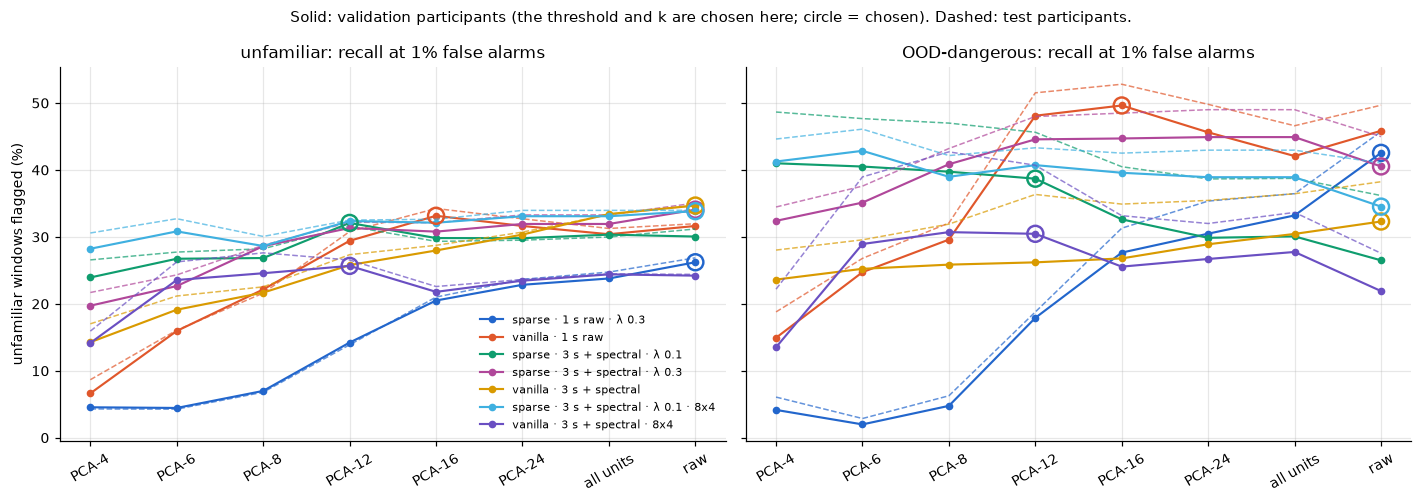

In [12]:
FIG_DIR = Path.cwd() / 'figures'
FIG_DIR.mkdir(exist_ok = True)
# colour follows the model, never its position; dense (non-sparse, 4 x 8) latents only, every model is in the tables
MODEL_C = {'gaussian · 1 s raw': '#2266cc', 'vanilla · 1 s raw': '#e0572b',              # validated in this order
           'gaussian · 3 s + spectral': '#0f9d6e', 'vanilla · 3 s + spectral': '#d99a00'}
DENSE = [m for m in MODEL_C if m in MODELS_VAL]
x = np.arange(len(REP_BY_DIMS))
fig, axes = plt.subplots(1, 2, figsize = (13, 4.6), sharey = True)
for ax, what in zip(axes, ['unfamiliar', 'OOD-dangerous']):
    for m in DENSE:
        part = step1[step1['model'] == m].groupby('representation')
        v = part[f'val flagged, {what} (%)'].mean().reindex(REP_BY_DIMS)
        t = part[f'test flagged, {what} (%)'].mean().reindex(REP_BY_DIMS)
        ax.plot(x, v, '-o', color = MODEL_C[m], ms = 4, lw = 1.4, label = m)
        ax.plot(x, t, '--', color = MODEL_C[m], lw = 1.0, alpha = .7)
        j = REP_BY_DIMS.index(chosen[m])
        ax.scatter([j], [v.iloc[j]], s = 110, facecolor = 'none', edgecolor = MODEL_C[m], lw = 1.6, zorder = 5)
    ax.set_xticks(x, REP_BY_DIMS, rotation = 30)
    ax.set(ylabel = f'{what} windows flagged (%)' if what == 'unfamiliar' else '', title = f'{what}: recall at 1% false alarms')
    ax.grid(alpha = .3)
axes[0].legend(fontsize = 7.5, frameon = False, loc = 'lower right')
fig.suptitle('Solid: validation participants (the threshold and k are chosen here; circle = chosen). Dashed: test participants.', fontsize = 9.5)
plt.tight_layout(); fig.savefig(FIG_DIR / '05_step1_recall_by_representation.png', dpi = 160); plt.show()

### 6.3 Task by task at the tuned threshold

Share of each task's test windows flagged with the chosen representation and the 1% false-alarm threshold, mean of
seeds. Compare with section 4 (the ankle rule): the first four columns should sit near 1 instead of near 0, and every
other column should rise.

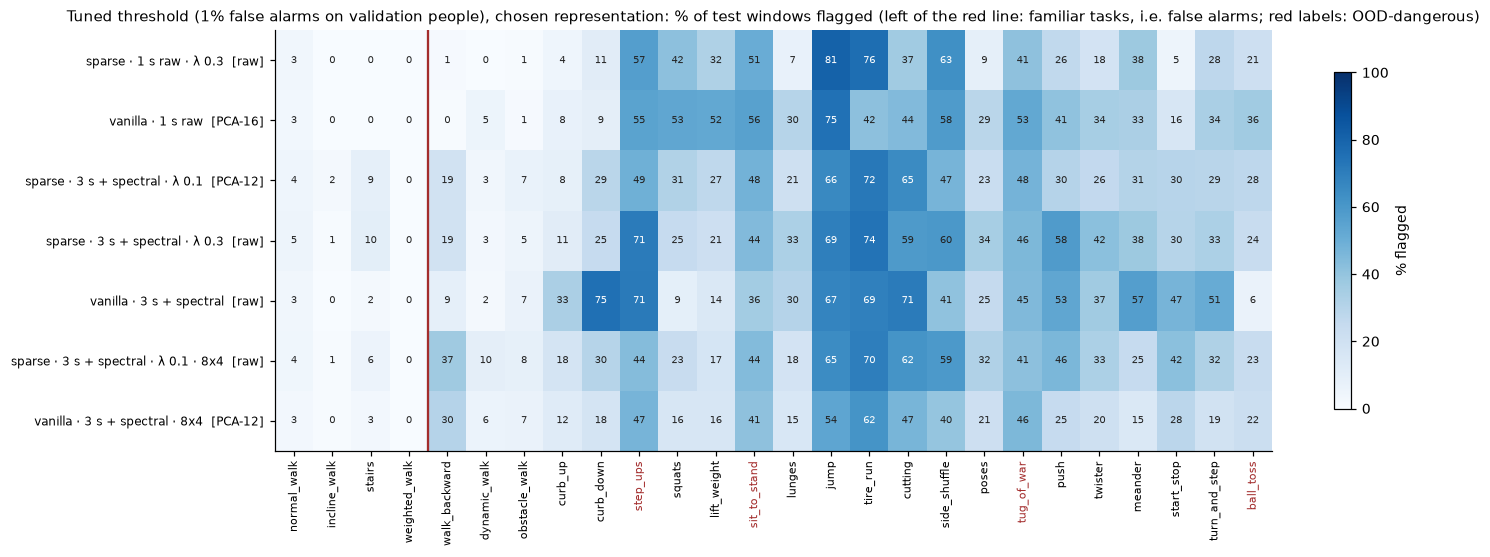

In [13]:
grid = pd.concat([per_task_tuned.xs((m, chosen[m]), level = ('model', 'representation')).mean().rename(m) for m in MODELS_VAL], axis = 1).T
grid = grid.reindex(columns = TASKS)
fig, ax = plt.subplots(figsize = (14, 0.42 * len(MODELS_VAL) + 2.2))
im = ax.imshow(grid.to_numpy(), aspect = 'auto', cmap = 'Blues', vmin = 0, vmax = 100)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        ax.text(j, i, f'{v:.0f}', ha = 'center', va = 'center', fontsize = 6.5, color = 'white' if v > 60 else '#222')
ax.set_xticks(range(len(TASKS)), TASKS, rotation = 90, fontsize = 7.5)
ax.set_yticks(range(len(MODELS_VAL)), [f'{m}  [{chosen[m]}]' for m in MODELS_VAL], fontsize = 8)
ax.axvline(len(FAMILIAR) - .5, color = '#a32d2d', lw = 1.5)
for t in nt.OOD_DANGEROUS_TASKS:
    ax.get_xticklabels()[TASKS.index(t)].set_color('#a32d2d')
ax.set_title('Tuned threshold (1% false alarms on validation people), chosen representation: % of test windows flagged '
             '(left of the red line: familiar tasks, i.e. false alarms; red labels: OOD-dangerous)', fontsize = 9.5)
fig.colorbar(im, ax = ax, shrink = .8, label = '% flagged'); plt.tight_layout()
fig.savefig(FIG_DIR / '05_step1_per_task.png', dpi = 160); plt.show()

### 6.4 The trade-off behind the 1% target

For the dense latents (plain and Gaussian-NLL) in their chosen representation: thresholds set on validation for several false-alarm targets,
then the false alarms and recall they give on the test participants (mean of seeds). The ankle rule is the marker.
Where the curve bends is where a different target would be worth it.

false alarms (%)                          recall, unfamiliar (%)                          recall, OOD-dangerous (%)                         
model      vanilla · 1 s raw vanilla · 3 s + spectral      vanilla · 1 s raw vanilla · 3 s + spectral         vanilla · 1 s raw vanilla · 3 s + spectral
target (%)                                                                                                                                              
0.2                      0.8                      1.2                   21.0                     21.6                      39.0                     21.1
0.5                      1.2                      1.6                   26.5                     28.4                      44.4                     30.4
1.0                      1.7                      2.0                   34.2                     34.7                      52.8                     38.2
2.0                      2.3                      2.7                   44.0                     42.4                      63.2                     48.5
3.0                      2.8                      3.2                   51.5                     47.4                      71.4                     54.7
5.0                      3.7                      4.2                   61.0                     55.2                      81.4                     63.7

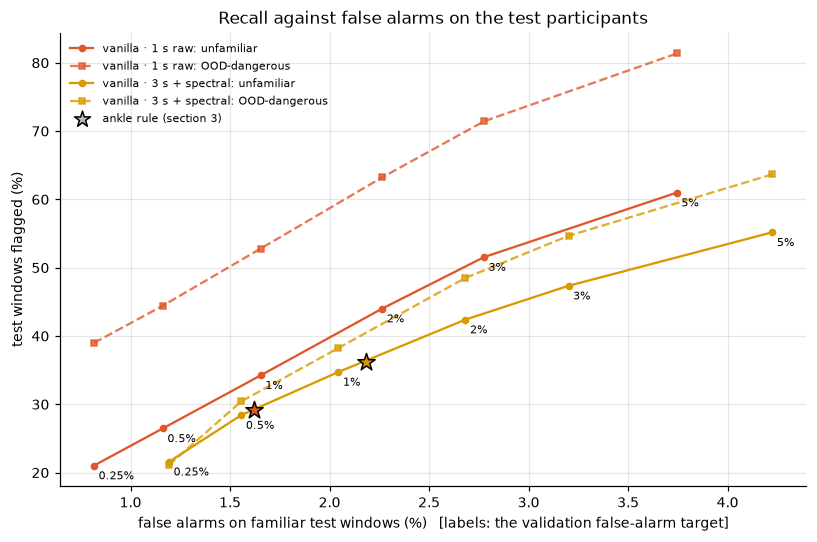

In [14]:
TARGETS = (0.25, 0.5, 1.0, 2.0, 3.0, 5.0)
curves = []
for r in with_val[with_val['model'].isin(DENSE)].itertuples():
    rep = next(k for k in REPRESENTATIONS if rep_label(k) == chosen[r.model])
    labels_v, labels_t = val_labels[r.run], test_labels[r.run]
    keep_v = pd.MultiIndex.from_frame(labels_v[['rec', 'end']]).isin(COMMON_VAL)
    keep_t = pd.MultiIndex.from_frame(labels_t[['rec', 'end']]).isin(COMMON)
    lab_v, lab_t = labels_v[keep_v].reset_index(drop = True), labels_t[keep_t].reset_index(drop = True)
    _, val, test = ns.get_split_scores(r.run, exports[r.run], val_exports[r.run], rep, CACHE)
    filt_v, filt_t = ns.get_filtered(val[keep_v], lab_v), ns.get_filtered(test[keep_t], lab_t)
    tasks_t, cls_t = lab_t['task'].astype(str).to_numpy(), lab_t['controller_class'].astype(str).to_numpy()
    fam_t = np.isin(tasks_t, FAMILIAR)
    for target in TARGETS:
        thr = ns.tune_threshold(filt_v, lab_v, FAMILIAR, target)
        curves.append({'model': r.model, 'seed': r.seed, 'target (%)': target, 'false alarms (%)': 100 * (filt_t[fam_t] > thr).mean(),
                       'recall, unfamiliar (%)': 100 * (filt_t[~fam_t] > thr).mean(),
                       'recall, OOD-dangerous (%)': 100 * (filt_t[cls_t == 'OOD-dangerous'] > thr).mean()})
curves = pd.DataFrame(curves)
mean_curves = curves.groupby(['model', 'target (%)']).mean(numeric_only = True).reset_index()
display(mean_curves.round(1).pivot(index = 'target (%)', columns = 'model', values = ['false alarms (%)', 'recall, unfamiliar (%)', 'recall, OOD-dangerous (%)']))

fig, ax = plt.subplots(figsize = (7.5, 5))
for m in DENSE:
    part = mean_curves[mean_curves['model'] == m]
    ax.plot(part['false alarms (%)'], part['recall, unfamiliar (%)'], '-o', color = MODEL_C[m], ms = 4, label = f'{m}: unfamiliar')
    ax.plot(part['false alarms (%)'], part['recall, OOD-dangerous (%)'], '--s', color = MODEL_C[m], ms = 4, alpha = .8, label = f'{m}: OOD-dangerous')
    ankle_m = summary[(summary['model'] == m) & (summary['setting'] == SETTINGS[0])].mean(numeric_only = True)
    ax.scatter([ankle_m['false alarms (%)']], [ankle_m['recall, unfamiliar (%)']], marker = '*', s = 140, color = MODEL_C[m], edgecolor = 'k', zorder = 5)
    for _, row in part.iterrows():
        ax.annotate(f"{row['target (%)']:g}%", (row['false alarms (%)'], row['recall, unfamiliar (%)']), fontsize = 7, xytext = (3, -9), textcoords = 'offset points')
ax.scatter([], [], marker = '*', s = 120, color = '#bbb', edgecolor = 'k', label = 'ankle rule (section 3)')
ax.set(xlabel = 'false alarms on familiar test windows (%)   [labels: the validation false-alarm target]',
       ylabel = 'test windows flagged (%)', title = 'Recall against false alarms on the test participants')
ax.grid(alpha = .3); ax.legend(fontsize = 7.5, frameon = False); plt.tight_layout()
fig.savefig(FIG_DIR / '05_step1_operating_curve.png', dpi = 160); plt.show()

### 6.5 What changed

- **A threshold set on held-out people does not transfer exactly to other people.** The 1% false-alarm target on the
  validation participants gives 1.7 to 2.0% false alarms on the test participants for the vanilla latents (0.8 to 1.2%
  for a 0.25% target), and the ankle rule's 99.5th percentile of training people gave 1.6 to 2.2% in section 3. The
  familiar score level differs between people by about a factor of two in false alarms, so the false-alarm rate an
  exoskeleton sees is set by its wearer, not by the training set. A short calibration bout of familiar walking per
  wearer is the natural fix.
- **Tuning the threshold alone buys little recall at matched false alarms.** On the vanilla 1 s latent, 29 to 32% of
  unfamiliar windows (1.6 to 1.8% false alarms); on the vanilla 3 s + spectral latent nothing (36 to 35% at 2.2 to
  2.0%). The ankle rule already sat on the same trade-off curve.
- **Fewer dimensions help the vanilla 1 s latent, and only that one.** Validation picks PCA-16 for it, and on test it
  flags 34.2 ± 6.0% of unfamiliar and 52.8 ± 10.0% of OOD-dangerous windows at 1.7% false alarms, against 29.2 ± 4.0%
  and 44.9 ± 7.1% at 1.6% under the ankle rule; AUROC is unchanged (0.883 against 0.887; 0.968 both). For the 3 s +
  spectral and the sparse latents validation keeps the raw latent, and the projections cost recall below 12 to 16
  components everywhere. With three seeds the ±6 to ±10 point spread puts PCA-16 against raw on the same model within
  noise: the direction agrees with the Science Robotics result, the size is not established.
- **The false-alarm target is the real lever.** On the vanilla 1 s latent (PCA-16), raising the target from 1 to 2%
  takes recall from 34 to 44% of unfamiliar and from 53 to 63% of OOD-dangerous windows at 2.3% false alarms; a 5%
  target flags 61% and 81% at 3.7%. The curve has no knee: recall at any low false-alarm rate is bounded by the
  ranking (AUROC 0.88), because unfamiliar scores straddle the familiar range (section 5). Which target to run is a
  controller decision, the share of walking windows that may be handed to the fallback controller, not a detector one.
- **Task by task** (vanilla 1 s, PCA-16, 1% target): jumping 75%, side shuffle 58%, sit-to-stand 56%, step-ups 55%,
  squats and lifting 52 to 53%, tug of war 53%; the ball toss rises to 36% (23% under the ankle rule) and standing
  poses to 29%. Near-familiar walking stays unflagged (walking backward 0%, obstacle walk 1%, dynamic walk 5%, curb up
  8%), and the few false alarms fall on normal walking (3%), none on incline, weighted or stair walking.

## 7. Adding a model or a score

- **A new model** (another seed, variant, or family such as a VAE): train it so that its run folder under
  `notebooks/nature/model_exploration/runs/` (any subfolder) holds `config.json`, `summary.json` and `latents.npz`
  with the arrays `rows`, `rec`, `end`, `z`, `recon_mse` and `is_train`, as `ml/nature/awareness/train_ae.py` writes
  them, and with its folder named `<stem>_s<seed>`. Rerun this notebook: the run is discovered, scored and added to
  every table and figure. Its `config.json` needs `inputs` (the window table its `rows` index); `variant`,
  `sparsity_weight` and `latent` are used for the label when present, otherwise the stem is.
- **A new score**: add a function `(export, fit_idx, cal_idx) -> (calibration scores, test scores)` to `SCORES` in
  `_novelty_scores.py`, larger meaning more unfamiliar. It is evaluated with the same protocol.
- If a new model exports a different set of test windows, every model is compared on the windows all of them share;
  the count is printed in section 1.

## 8. What this shows

**For the awareness pipeline**

- **Use LOF on a vanilla latent as the novelty baseline.** The 1 s vanilla AE is the stronger choice for safety: it
  ranks the OOD-dangerous tasks best and needs no extra 2 s of history. The 3 s + spectral vanilla flags slightly more
  unfamiliar windows overall.
- **Do not feed the sparse latents to LOF.** If their novelty units are used, score them directly (their activity
  against training windows) as a separate score in `SCORES`.
- **Set the operating point per wearer, and choose the false-alarm target as a controller decision.** Section 6: a
  threshold set on four held-out people misses its false-alarm target by about a factor of two on four others, and
  recall at matched false alarms is bounded by the ranking, not by the rule. Run the vanilla 1 s latent through 16
  principal components, and calibrate the threshold on a short familiar-walking bout of the wearer.
- **Quiet, posture-driven movement needs another signal.** Standing poses and the ball toss look familiar to every
  latent here, the same failure the ankle paper reported for standing. A regime classifier (notebook 06) or posture
  features such as thigh pitch are the candidates.

**Limits**

- Sections 3 to 5 compare models on the test participants; section 6 chooses the representation and the threshold on
  the validation participants and reports test once, but the model ranking of sections 3 to 5 was still read off test.
- k = 20 follows the ankle paper and was not tuned; the 99.5th-percentile rule is replaced in section 6 by a
  validation false-alarm target. The 75 / 25 fit and calibration split of the exported training windows is fixed.
- Unfamiliar includes near-familiar tasks (curbs, obstacle and dynamic walking, walking backwards); flagging them
  rarely may be acceptable, which is why results are given per task.
- Detection delay is not measured yet; windows are scored one by one, with the 0.5 s causal median before the
  threshold.